<h1>Notebook para S2 </h1>

In [1]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import hamming
import gudhi as gd
import seaborn as sns
from statistics import mode
import multiprocessing
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
import gudhi as gd
# from scipy.spatial.distance import hamming
import plotly.graph_objs as go
import networkx as nx
import plotly.graph_objects as go
import plotly.io as pio
from networkx.utils import not_implemented_for, pairwise
from concurrent.futures import ThreadPoolExecutor, as_completed

from module_functions import *

<h2>Se extrae la información </h2>

In [2]:
info=pd.read_csv('data/pscplos1246.blast',sep='\t',header=None)

names=pd.read_csv('data/Actinos.ids',sep='\t',dtype='object',header=None)

<h2>Se crean los data frames</h2>

In [3]:
from module_functions import *

In [10]:
df_by_pathway,df_by_pathway_drop_duplicate,representative_genomes=get_df_by_pathway(info)

<h2> Se crea el complejo simplicial</h2>

In [11]:
complex_pathways=get_complex_by_pathways(df_by_pathway_drop_duplicate)

<h2>Se buscan los uno hoyos</h2>

In [12]:
df_R5P={'R5P_AMINOACIDS':df_by_pathway['R5P_AMINOACIDS']}
representative_genomes_R5P={'R5P_AMINOACIDS':representative_genomes['R5P_AMINOACIDS']}
drop_dup_R5P={'R5P_AMINOACIDS':df_by_pathway_drop_duplicate['R5P_AMINOACIDS']}
compl_R5P={'R5P_AMINOACIDS':complex_pathways['R5P_AMINOACIDS']}

In [11]:
genus=set()
for i in list(traduced_df(drop_dup_R5P['R5P_AMINOACIDS'],names).index):
    genus.add(i.split(' ')[0])
len(genus)

30

In [12]:
list(traduced_df(drop_dup_R5P['R5P_AMINOACIDS'],names).index)[0].split(' ')

['Rhodococcus', 'jostii', 'RHA1', 'NC_008268.1']

In [13]:
holes=get_holes_by_pathways_no_fill(compl_R5P,drop_dup_R5P)

se buscan ciclos en el tiempo 1.0 para R5P_AMINOACIDS
se buscan ciclos en el tiempo 2.0 para R5P_AMINOACIDS
Se encontró el ciclo [12, 23, 11, 1] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [36, 30, 27, 11] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [27, 16, 23, 11] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [36, 22, 23, 11] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [13, 27, 11, 1] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [31, 8, 1, 0] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [18, 36, 11, 1] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [29, 22, 21, 10] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [11, 26, 2, 1] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [40, 34, 29, 10] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [42, 30, 29, 10] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [18, 24, 2, 1] en el tiempo 1.0 para R5P_AMINOACIDS
Se

In [14]:
holes_no_names,holes_names,holes_per_filt_lvl=holes

<h1>Contar las enzimas que que cambiaron en los hoyos encontrados</h1>

In [15]:
complejo_R5P=compl_R5P['R5P_AMINOACIDS']
cycles_R5P=holes_per_filt_lvl['R5P_AMINOACIDS']

In [100]:
from IPython.display import Image, display
def visual(simplex_tree, filtration_value, path, family,cycles=None,index=None,vertex_names=None, save_filename=None, plot_size=1, dpi=600):

    #Construcción del grafo asociado al complejo simplicial
    G = nx.Graph()
    triangles = []  # List to store triangles (3-nodes simplices)
    edges=[]
    #filt_levels=set(np.asanyarray(list(complejo_R5P[1].get_filtration()))[:,1])
    prueba=True
    for simplex, filt in simplex_tree.get_filtration():
        if len(simplex) == 1:
            G.add_node(simplex[0])
        if len(simplex) == 2:
            G.add_edge(simplex[0], simplex[1])
        if filt>1 and prueba==True:
            pos = nx.spring_layout(G,dim=2,seed=42)
            prueba=False
                
        if filt <= filtration_value:
            if len(simplex) == 2:
                edges.append(simplex)
            elif len(simplex) == 3:
                triangles.append(simplex)  
    #pos = nx.spring_layout(G,dim=2,seed=42)


    

    #Graficar triángulos
    triangle_traces = []
    for triangle in triangles:
        x0, y0 = pos[triangle[0]]
        x1, y1 = pos[triangle[1]]
        x2, y2 = pos[triangle[2]]
        triangle_trace = go.Scatter(x=[x0, x1, x2, x0, None], y=[y0, y1, y2, y0, None], fill='toself', mode='lines', line=dict(width=0), fillcolor='rgba(255,0,0,0.2)')
        triangle_traces.append(triangle_trace)


        #Graficar 1-hoyos
    cycle_traces=[]
    if cycles != None:
        for filt_lvl in range(0,filtration_value+1):
            if filt_lvl in cycles.keys():
                cycles_at_lvl_filt=cycles[filt_lvl]

                for cycle in cycles_at_lvl_filt:
                    x=[]
                    y=[]
                    for v in cycle:
                        coords=pos[v]
                        x.append(coords[0])
                        y.append(coords[1])
                    x.append(None)
                    y.append(None)
                    cycle_trace=go.Scatter(x=x, y=y, fill='toself', mode='lines', line=dict(width=0), fillcolor='rgba(0,255,0,0.4)')
                    cycle_traces.append(cycle_trace)

    
        #Graficar Nodos
    x_values, y_values = zip(*[pos[node] for node in G.nodes()])
    node_labels = [vertex_names[node] if vertex_names else str(node) for node in G.nodes()]
    node_trace = go.Scatter(x=x_values, y=y_values, mode='markers+text', hoverinfo='text', marker=dict(size=14), text=node_labels, textposition='top center', textfont=dict(size=14))
    #Graficar aristas
    edge_traces = []
    for edge in edges:
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace = go.Scatter(x=[x0, x1, None], y=[y0, y1, None], mode='lines', line=dict(width=3, color='rgba(0,0,0,0.5)'))
        edge_traces.append(edge_trace)
    

        


    
    titulo='Complejo simplicial de la ruta '+path+' en '+family+' para nivel de filtración '+str(filtration_value)
    # Configure the layout of the plot
    layout = go.Layout(showlegend=False, hovermode='closest', xaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')), yaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')),title=dict(
            text=titulo ,
            x=0.5,
            xanchor='center',
            font=dict(size=24, family='Arial, sans-serif')
        ))
    fig = go.Figure(data=edge_traces + triangle_traces + [node_trace]+cycle_traces, layout=layout,)
    
    # Set the figure size
    fig.update_layout(width=plot_size * dpi, height=plot_size * dpi)

    # Show the figure
    #fig.write_image('M.png')
    filename=path+'_'+family+'_t_'+str(filtration_value)+'.html'
    plotly.offline.plot(fig, filename=filename)
        # Render the figure to a PNG image in memory
    img_bytes = fig.to_image(format="png", width=plot_size * dpi, height=plot_size * dpi)

    # Display the image in the Jupyter Notebook
    display(Image(data=img_bytes))

    return fig

In [19]:
import plotly.graph_objs as go
import networkx as nx
import plotly.io as pio

def visual_complex(simplex_tree, filtration_value, title, cycles=None, vertex_names=None, save_filename=None):
    # Construcción del grafo asociado al complejo simplicial
    G = nx.Graph()
    triangles = []  # Lista para almacenar triángulos (simplices de 3 nodos)
    edges = []
    prueba = True

    for simplex, filt in simplex_tree.get_filtration():
        if len(simplex) == 1:
            G.add_node(simplex[0])
        if len(simplex) == 2:
            G.add_edge(simplex[0], simplex[1])
        if filt > 1 and prueba:
            pos = nx.spring_layout(G, dim=2, seed=42)
            prueba = False
                
        if filt <= filtration_value:
            if len(simplex) == 2:
                edges.append(simplex)
            elif len(simplex) == 3:
                triangles.append(simplex)

    if prueba==True:
        pos = nx.spring_layout(G, dim=2, seed=42)
    
    # Graficar triángulos
    triangle_traces = []
    for triangle in triangles:
        x0, y0 = pos[triangle[0]]
        x1, y1 = pos[triangle[1]]
        x2, y2 = pos[triangle[2]]
        triangle_trace = go.Scatter(x=[x0, x1, x2, x0, None], y=[y0, y1, y2, y0, None], fill='toself', mode='lines', line=dict(width=0), fillcolor='rgba(255,0,0,0.1)')
        triangle_traces.append(triangle_trace)

    # Graficar ciclos
    cycle_traces = []
    if cycles is not None:
        for filt_lvl in range(0, filtration_value + 1):
            if filt_lvl in cycles.keys():
                cycles_at_lvl_filt = cycles[filt_lvl]
                for cycle in cycles_at_lvl_filt:
                    x = []
                    y = []
                    for v in cycle:
                        coords = pos[v]
                        x.append(coords[0])
                        y.append(coords[1])
                    x.append(None)
                    y.append(None)
                    cycle_trace = go.Scatter(x=x, y=y, fill='toself', mode='lines', line=dict(width=0), fillcolor='rgba(0,255,0,0.1)')
                    cycle_traces.append(cycle_trace)

    # Graficar nodos
    x_values, y_values = zip(*[pos[node] for node in G.nodes()])
    node_labels = [vertex_names[node] if vertex_names else str(node) for node in G.nodes()]
    node_trace = go.Scatter(x=x_values, y=y_values, mode='markers+text', hoverinfo='text', marker=dict(size=14), text=node_labels, textposition='top center', textfont=dict(size=14))
    
    # Graficar aristas
    edge_traces = []
    for edge in edges:
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace = go.Scatter(x=[x0, x1, None], y=[y0, y1, None], mode='lines', line=dict(width=3, color='rgba(0,0,0,1)'))
        edge_traces.append(edge_trace)


    # Configurar el layout del gráfico (sin ejes coordenados)
    layout = go.Layout(
        showlegend=False,
        hovermode='closest',
        xaxis=dict(
            showgrid=False,  # Sin cuadrícula
            zeroline=False,  # Sin línea cero
            showline=False,  # Sin línea del eje
            ticks='',  # Sin marcas en el eje X
            visible=False  # Ocultar el eje X
        ),
        yaxis=dict(
            showgrid=False,  # Sin cuadrícula
            zeroline=False,  # Sin línea cero
            showline=False,  # Sin línea del eje
            ticks='',  # Sin marcas en el eje Y
            visible=False  # Ocultar el eje Y
        ),
        title=dict(
            text=title,
            x=0.5,
            xanchor='center',
            font=dict(size=24, family='Arial, sans-serif')
        ),
        paper_bgcolor='white',  # Fondo blanco
        plot_bgcolor='white'    # Fondo blanco en el área del gráfico
    )

    fig = go.Figure(data=edge_traces + triangle_traces + [node_trace] + cycle_traces, layout=layout)

    

    # Establecer el tamaño de la figura
    plot_size=1
    dpi=600
    fig.update_layout(width=plot_size * dpi, height=plot_size * dpi)

    # Mostrar la figura
    filename = f'{title}.html'
    plotly.offline.plot(fig, filename=filename)

    # Guardar la figura como SVG (si se especifica un nombre de archivo)
    if save_filename:
        fig.write_image(f"{save_filename}.svg", format="svg", width=plot_size * dpi, height=plot_size * dpi)

    return fig


In [20]:
simplex_tree.get_filtration()

In [16]:
fig1=visual_complex(complejo_R5P[1],1,title='hola',cycles=cycles_R5P)
fig2=visual_complex(complejo_R5P[1],2,title='hola',cycles=cycles_R5P)
fig3=visual_complex(complejo_R5P[1],3,title='hola',cycles=cycles_R5P)

In [22]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Definir tamaño dinámico para los títulos y subtítulos
height = 600
width = 1200
font_size = int(height / 50)  # Ajustar tamaño de fuente proporcionalmente al alto de la figura

# Crear subgráficos en una fila
fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=('Primer nivel', 'Segundo nivel', 'Tercer nivel'),
    horizontal_spacing=0.05,  # Espacio horizontal entre gráficos
    vertical_spacing=1
)

# Añadir las trazas de cada figura al subgráfico correspondiente
for trace in fig1.data:
    fig.add_trace(trace, row=1, col=1)
for trace in fig2.data:
    fig.add_trace(trace, row=1, col=2)
for trace in fig3.data:
    fig.add_trace(trace, row=1, col=3)

# Actualizar el diseño del gráfico
fig.update_layout(
    title_text='\\textbf{Complejo de la ruta R5P\_AMINOACIDS del linaje Streptosporangiaceae}',
    title_x=0.5,  # Centrar el título
    title_y=0.9,
    showlegend=False,  # Ocultar leyenda si no es necesaria
    height=height,        # Altura total del gráfico
    width=width,        # Ancho total del gráfico
    plot_bgcolor='white',  # Fondo blanco para toda la figura
    paper_bgcolor='white',  # Fondo blanco para el área de la figura
    xaxis=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    yaxis=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    xaxis2=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    yaxis2=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    xaxis3=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    yaxis3=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    font=dict(size=font_size),  # Ajustar tamaño de fuente proporcional
    title_font=dict(size=int(font_size * 3))
    ,  # Ajustar título más grande proporcionalmente
    margin=dict(t=130, b=140, l=50, r=50),  # Ajustar márgenes para evitar que se encimen los títulos
)

# Guardar la figura en formato SVG sin mostrarla
fig.write_image("visual_complex_R5P.svg", format='svg')


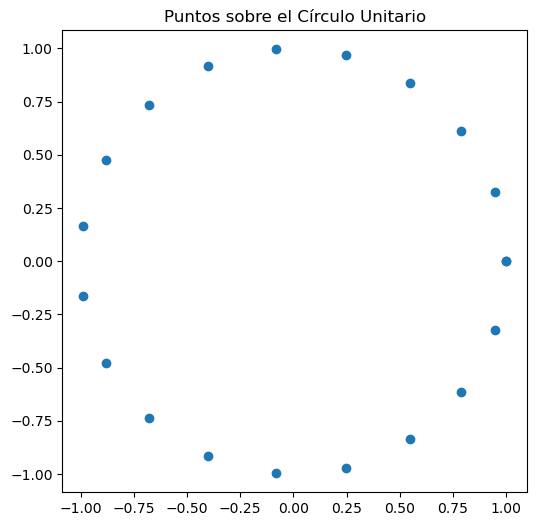

usetex mode requires TeX.


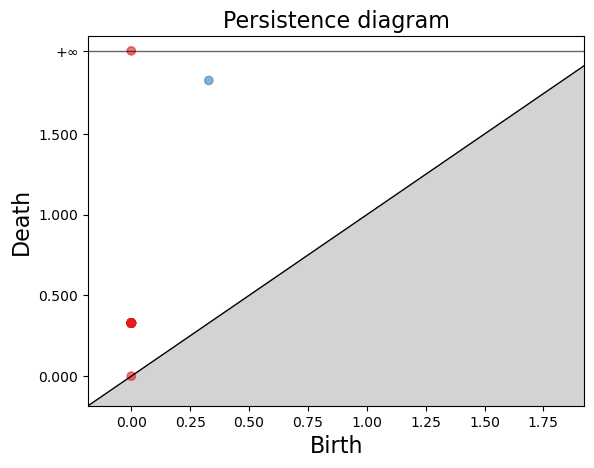

In [2]:
import numpy as np
import gudhi as gd
import matplotlib.pyplot as plt

# Generar los puntos sobre el círculo unitario
num_points = 20
theta = np.linspace(0, 2 * np.pi, num_points)
x = np.cos(theta)
y = np.sin(theta)

# Visualizar los puntos sobre el círculo unitario
plt.figure(figsize=(6,6))
plt.plot(x, y, 'o')
plt.title("Puntos sobre el Círculo Unitario")
plt.axis('equal')
plt.show()

# Crear una distancia de matriz entre los puntos
points = np.column_stack((x, y))
distance_matrix = np.linalg.norm(points[:, None] - points, axis=2)

# Construcción del complejo simplicial utilizando la matriz de distancias
rips_complex = gd.RipsComplex(distance_matrix=distance_matrix)

# Construcción del árbol simplicial persistente
simplex_tree = rips_complex.create_simplex_tree(max_dimension=2)

# Calcular la homología persistente
persistence = simplex_tree.persistence()

# Visualizar el diagrama de persistencia
gd.plot_persistence_diagram(persistence)
plt.show()


In [3]:
a=find_all_cycles_no_fill(['hola',[persistence,simplex_tree]])

se buscan ciclos en el tiempo 2.4492935982947064e-16 para hola
se buscan ciclos en el tiempo 0.3291891805614673 para hola
se buscan ciclos en el tiempo 0.3291891805614676 para hola
se buscan ciclos en el tiempo 0.32918918056146773 para hola
se buscan ciclos en el tiempo 0.3291891805614678 para hola
se buscan ciclos en el tiempo 0.32918918056146784 para hola
se buscan ciclos en el tiempo 0.3291891805614679 para hola
se buscan ciclos en el tiempo 0.32918918056146795 para hola
Se encontró el ciclo [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 0] en el tiempo 0.3291891805614679 para hola
se buscan ciclos en el tiempo 0.32918918056146806 para hola
Se encontró el ciclo [18, 17, 16, 15, 14, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1, 19] en el tiempo 0.32918918056146795 para hola
se buscan ciclos en el tiempo 0.6493989384093666 para hola
Se encontró el ciclo [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 0] en el tiempo 0.32918918056146806 para hola
se bu

In [4]:
fig1=visual_complex(simplex_tree,0.3291891805614679,title='hola2',cycles=a[2])
fig2=visual_complex(simplex_tree,1.6743329565250573,title='hola2',cycles=a[2])
fig3=visual_complex(simplex_tree,1.8315466533101148,title='hola2',cycles=a[2])

In [6]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Definir tamaño dinámico para los títulos y subtítulos
height = 600
width = 1200
font_size = int(height / 50)  # Ajustar tamaño de fuente proporcionalmente al alto de la figura

# Crear subgráficos en una fila
fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=('a)', 'b)', 'c)'),
    horizontal_spacing=0.05,  # Espacio horizontal entre gráficos
    vertical_spacing=1
)

# Añadir las trazas de cada figura al subgráfico correspondiente
for trace in fig1.data:
    fig.add_trace(trace, row=1, col=1)
for trace in fig2.data:
    fig.add_trace(trace, row=1, col=2)
for trace in fig3.data:
    fig.add_trace(trace, row=1, col=3)

# Actualizar el diseño del gráfico
fig.update_layout(
    title_x=0.5,  # Centrar el título
    title_y=0.9,
    showlegend=False,  # Ocultar leyenda si no es necesaria
    height=height,        # Altura total del gráfico
    width=width,        # Ancho total del gráfico
    plot_bgcolor='white',  # Fondo blanco para toda la figura
    paper_bgcolor='white',  # Fondo blanco para el área de la figura
    xaxis=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    yaxis=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    xaxis2=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    yaxis2=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    xaxis3=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    yaxis3=dict(showline=False, showgrid=False, zeroline=False, showticklabels=False),
    font=dict(size=font_size),  # Ajustar tamaño de fuente proporcional
    title_font=dict(size=int(font_size * 3))
    ,  # Ajustar título más grande proporcionalmente
    margin=dict(t=130, b=140, l=50, r=50),  # Ajustar márgenes para evitar que se encimen los títulos
)

# Guardar la figura en formato SVG sin mostrarla
fig.write_image("visual_complex_circle.svg", format='svg')


In [7]:
b=np.asanyarray(list(simplex_tree.get_filtration()),dtype=object)[:,1]
b[b>0].max()

1.99316898601334

In [50]:
def visual(simplex_tree, filtration_value, path, family,vertex_names=None, save_filename=None, plot_size=1, dpi=600, pos=None):
    G = nx.Graph()
    triangles = []  # List to store triangles (3-nodes simplices)

    for simplex, filt in simplex_tree.get_filtration():
        if len(simplex) == 1:
            G.add_node(simplex[0])
        if filt <= filtration_value:
            if len(simplex) == 2:
                G.add_edge(simplex[0], simplex[1])
            elif len(simplex) == 3:
                triangles.append(simplex)  

    
    
    # Calculate node positions if not provided
    if pos is None:
        pos = nx.spring_layout(G,dim=2,seed=42)
    
    # Node trace
    x_values, y_values = zip(*[pos[node] for node in G.nodes()])
    node_labels = [vertex_names[node] if vertex_names else str(node) for node in G.nodes()]
    node_trace = go.Scatter(x=x_values, y=y_values, mode='markers+text', hoverinfo='text', marker=dict(size=14), text=node_labels, textposition='top center', textfont=dict(size=14))
        # Edge traces
    edge_traces = []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace = go.Scatter(x=[x0, x1, None], y=[y0, y1, None], mode='lines', line=dict(width=3, color='rgba(0,0,0,0.5)'))
        edge_traces.append(edge_trace)
    
    # Triangle traces
    triangle_traces = []
    for triangle in triangles:
        x0, y0 = pos[triangle[0]]
        x1, y1 = pos[triangle[1]]
        x2, y2 = pos[triangle[2]]
        triangle_trace = go.Scatter(x=[x0, x1, x2, x0, None], y=[y0, y1, y2, y0, None], fill='toself', mode='lines+markers', line=dict(width=2), fillcolor='rgba(255,0,0,0.2)')
        triangle_traces.append(triangle_trace)
    titulo='Complejo simplicial de la ruta '+path+' en '+family+' para nivel de filtración '+str(filtration_value)
    # Configure the layout of the plot
    layout = go.Layout(showlegend=False, hovermode='closest', xaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')), yaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')),title=dict(
            text=titulo ,
            x=0.5,
            xanchor='center',
            font=dict(size=24, family='Arial, sans-serif')
        ))
    fig = go.Figure(data=edge_traces + triangle_traces + [node_trace], layout=layout,)
    
    # Set the figure size
    fig.update_layout(width=plot_size * dpi, height=plot_size * dpi)
    

    # Show the figure
    #fig.write_image('M.png')
    filename=path+'_'+family+'_t_'+str(filtration_value)+'.html'
    plotly.offline.plot(fig, filename=filename)
    

    return pos

In [105]:
get_resum_df(df_R5P,representative_genomes_R5P,names,compl_R5P,cycles_R5P)

KeyError: 1.0

In [26]:
complex_genus_R5P_AMINOACIDS={}
df_by_genus_R5P_AMINOACIDS_drop_duplicate={}
representative_genomes_by_genus_R5P_AMINOACIDS={}
df_by_genus_pathway_R5P_AMINOACIDS={}
for key in complex_genus_pathways.keys():
    if 'R5P_AMINOACIDS' in key:
        df_by_genus_pathway_R5P_AMINOACIDS[key]=df_by_genus_pathway[key]
        complex_genus_R5P_AMINOACIDS[key]=complex_genus_pathways[key]
        df_by_genus_R5P_AMINOACIDS_drop_duplicate[key]=df_by_genus_pathway_drop_duplicate[key]
        representative_genomes_by_genus_R5P_AMINOACIDS[key]=representative_genomes_genus_pathway[key]

In [27]:
len(df_by_genus_pathway_R5P_AMINOACIDS.keys())

193

In [28]:
holes_R5P_AMINOACIDS_GENUS=get_holes_by_pathways(complex_genus_R5P_AMINOACIDS,df_by_genus_R5P_AMINOACIDS_drop_duplicate)

se buscan ciclos en el tiempo 2.0 para Nocardia_R5P_AMINOACIDS
Se encontró el ciclo [3, 2, 1, 0] en el tiempo 1.0 para Nocardia_R5P_AMINOACIDS
se buscan ciclos en el tiempo 2.0 para Streptomyces_R5P_AMINOACIDS
Se encontró el ciclo [6, 13, 1, 0] en el tiempo 1.0 para Streptomyces_R5P_AMINOACIDS
Se encontró el ciclo [14, 5, 1, 0] en el tiempo 1.0 para Streptomyces_R5P_AMINOACIDS
Se encontró el ciclo [3, 2, 1, 0] en el tiempo 1.0 para Streptomyces_R5P_AMINOACIDS
Se encontró el ciclo [4, 10, 1, 0] en el tiempo 1.0 para Streptomyces_R5P_AMINOACIDS
Se encontró el ciclo [8, 15, 1, 0] en el tiempo 1.0 para Streptomyces_R5P_AMINOACIDS
Se encontró el ciclo [17, 12, 8, 0] en el tiempo 1.0 para Streptomyces_R5P_AMINOACIDS
Se encontró el ciclo [17, 16, 1, 0] en el tiempo 1.0 para Streptomyces_R5P_AMINOACIDS


In [29]:
a=get_resum_df(df_by_genus_pathway_R5P_AMINOACIDS,representative_genomes_by_genus_R5P_AMINOACIDS,names,complex_genus_R5P_AMINOACIDS,holes_R5P_AMINOACIDS_GENUS)

In [30]:
a[a['num_hoyos']!=0]

,num_columnas,num_hoyos,ciclos,ciclos por genero,duración hoyos
Nocardia_R5P_AMINOACIDS,5,1,[[[Nocardia otitidiscaviarum NBRC 14405 BAGD01...,"[[[Nocardia, Nocardia, Nocardia, Nocardia, Noc...",[1.0]
Streptomyces_R5P_AMINOACIDS,5,7,"[[[Streptomyces floridae JOAC01, Streptomyces ...","[[[Streptomyces, Streptomyces, Streptomyces, S...",[1.0]


In [31]:
len(holes_R5P_AMINOACIDS_GENUS['Nocardia_R5P_AMINOACIDS'])

1

In [32]:
df_holes_R5P_AMINOACIDS_droped_cols=get_df_by_pathway_make_hole_droped_cols(df_by_genus_R5P_AMINOACIDS_drop_duplicate,holes_R5P_AMINOACIDS)

KeyError: 'Rhodococcus_R5P_AMINOACIDS'

In [70]:
for i,j in df_holes_R5P_AMINOACIDS_droped_cols.items():
    if j==[]:
        continue
    else:
        print(i)

Nocardia_R5P_AMINOACIDS
Streptomyces_R5P_AMINOACIDS


In [72]:
contar=[]
for i in df_holes_R5P_AMINOACIDS_droped_cols['Nocardia_R5P_AMINOACIDS']:
    contar.extend(i)
for j in df_by_pathway['R5P_AMINOACIDS'].columns:
    print(j,contar.count(j))
    

phosphoribosyl_isomerase_A 0
imidazole_glycerol_phosphate_synthase_H 0
ribosephosphate_pyrophosphokinase 1
histidinol_dehydrogenase 1
imidazoleglycerol_phosphate_dehydratase 0


In [71]:
contar=[]
for i in df_holes_R5P_AMINOACIDS_droped_cols['Streptomyces_R5P_AMINOACIDS']:
    contar.extend(i)
for j in df_by_pathway['R5P_AMINOACIDS'].columns:
    print(j,contar.count(j))
    

phosphoribosyl_isomerase_A 0
imidazole_glycerol_phosphate_synthase_H 4
ribosephosphate_pyrophosphokinase 6
histidinol_dehydrogenase 4
imidazoleglycerol_phosphate_dehydratase 0


In [7]:
def visualize_simplicial_complex(simplex_tree, filtration_value, path, family,vertex_names=None, save_filename=None, plot_size=1, dpi=600, pos=None):
    G = nx.Graph()
    triangles = []  # List to store triangles (3-nodes simplices)
    
    for simplex, filt in simplex_tree.get_filtration():
        if filt <= filtration_value:
            if len(simplex) == 2:
                G.add_edge(simplex[0], simplex[1])
            elif len(simplex) == 1:
                G.add_node(simplex[0])
            elif len(simplex) == 3:
                triangles.append(simplex)
    
    # Calculate node positions if not provided
    if pos is None:
        pos = nx.spring_layout(G,dim=2)
    
    # Node trace
    x_values, y_values = zip(*[pos[node] for node in G.nodes()])
    node_labels = [vertex_names[node] if vertex_names else str(node) for node in G.nodes()]
    node_trace = go.Scatter(x=x_values, y=y_values, mode='markers+text', hoverinfo='text', marker=dict(size=14), text=node_labels, textposition='top center', textfont=dict(size=14))
        # Edge traces
    edge_traces = []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace = go.Scatter(x=[x0, x1, None], y=[y0, y1, None], mode='lines', line=dict(width=3, color='rgba(0,0,0,0.5)'))
        edge_traces.append(edge_trace)
    
    # Triangle traces
    triangle_traces = []
    for triangle in triangles:
        x0, y0 = pos[triangle[0]]
        x1, y1 = pos[triangle[1]]
        x2, y2 = pos[triangle[2]]
        triangle_trace = go.Scatter(x=[x0, x1, x2, x0, None], y=[y0, y1, y2, y0, None], fill='toself', mode='lines+markers', line=dict(width=2), fillcolor='rgba(255,0,0,0.2)')
        triangle_traces.append(triangle_trace)
    titulo='Complejo simplicial de la ruta '+path+' en '+family+' para nivel de filtración '+str(filtration_value)
    # Configure the layout of the plot
    layout = go.Layout(showlegend=False, hovermode='closest', xaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')), yaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')),title=dict(
            text=titulo ,
            x=0.5,
            xanchor='center',
            font=dict(size=24, family='Arial, sans-serif')
        ))
    fig = go.Figure(data=edge_traces + triangle_traces + [node_trace], layout=layout)
    
    # Set the figure size
    fig.update_layout(width=plot_size * dpi, height=plot_size * dpi)
    

    # Show the figure
    #fig.write_image('M.png')
    filename=path+'_'+family+'_t_'+str(filtration_value)+'.html'
    plotly.offline.plot(fig, filename=filename)
    

    return type(fig) 

In [30]:
def find_all_cycles(complex_dict):
    complex_path=complex_dict[0]
    persistence,simplex_tree=complex_dict[1]
    born_and_number = born_filtraton_value_holes(persistence)
    G=nx.Graph()
    born=born_and_number.keys()
    ciclos_dep=set()
    filtration=0
    for simplex, filt in simplex_tree.get_filtration():
        #if len(ciclos_dep)==num_holes:
         #   break
        
        if filtration!=filt and filtration in born:
            number=born_and_number[filtration]

            print('se buscan ciclos en el tiempo', filt,'para',complex_path)
            ciclos=minimum_cycle_basis(G,total=number)
            for ciclo in ciclos:
                if len(ciclo)>3:
                    print('Se encontró el ciclo',ciclo,'en el tiempo', filtration,'para',complex_path)
                    ciclos_dep.add(tuple(ciclo))
                    save_graph_visualization(G, filt, filt, save_filename=None, plot_size=1, dpi=600, pos=None)
                    #Se llena el hoyo
                    for i in ciclo:
                        for j in ciclo:
                            G.add_edge(i,j)
                            
            
        filtration=filt
        
        if len(simplex)==2:
            G.add_edge(simplex[0], simplex[1])


    #direc='pseudomonas_'+complex_path+'.txt'
    #f = open(direc, "a")
    #f.write(str(ciclos_dep))
    #f.close()
        

    return [complex_path,ciclos_dep]

In [29]:
import networkx as nx
import plotly.graph_objs as go
import plotly.offline

def save_graph_visualization(G, path, family, save_filename=None, plot_size=1, dpi=600, pos=None):
    """
    Dada una gráfica de NetworkX, guarda una visualización interactiva con el mismo formato de colores que la función original.
    
    Args:
    G (networkx.Graph): El grafo a visualizar.
    path (str): El nombre de la ruta (para el título y archivo).
    family (str): El nombre de la familia (para el título y archivo).
    save_filename (str, optional): El nombre de archivo para guardar el gráfico. Si no se proporciona, se genera uno automáticamente.
    plot_size (float, optional): Escala de tamaño para el gráfico. Por defecto es 1.
    dpi (int, optional): Resolución del gráfico. Por defecto es 600.
    pos (dict, optional): Posiciones de los nodos. Si no se proporciona, se usa `spring_layout`.
    
    Returns:
    None
    """
    # Colores de los diferentes tipos de simplices
    color_nodes = 'rgba(0,0,0,1)'  # Negros para vértices (nodos)
    color_edges = 'rgba(169,169,169,0.6)'  # Gris para aristas

    # Calcular las posiciones de los nodos si no se proporcionan
    if pos is None:
        pos = nx.spring_layout(G, dim=2)

    # Traza de los nodos (vértices de 0-simplices)
    x_values, y_values = zip(*[pos[node] for node in G.nodes()])
    node_trace = go.Scatter(
        x=x_values, y=y_values, mode='markers+text', hoverinfo='text', 
        marker=dict(size=14, color=color_nodes),  # Nodos en color negro
        text=[str(node) for node in G.nodes()], textposition='top center', 
        textfont=dict(size=14)
    )
    
    # Traza de las aristas (simples de 2 nodos)
    edge_traces = []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace = go.Scatter(
            x=[x0, x1, None], y=[y0, y1, None], mode='lines', 
            line=dict(width=3, color=color_edges)  # Aristas en color gris
        )
        edge_traces.append(edge_trace)
    
    # Titulo de la visualización
    titulo = f'Visualización del grafo {path} en {family}'
    
    # Configuración del layout
    layout = go.Layout(
        showlegend=False, 
        hovermode='closest', 
        xaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')), 
        yaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')),
        title=dict(text=titulo, x=0.5, xanchor='center', font=dict(size=24, family='Arial, sans-serif'))
    )
    
    # Crear la figura
    fig = go.Figure(data=edge_traces + [node_trace], layout=layout)
    
    # Establecer el tamaño de la figura
    fig.update_layout(width=plot_size * dpi, height=plot_size * dpi)
    
    # Generar el nombre del archivo si no se proporciona
    if save_filename is None:
        save_filename = f'{path}_{family}_graph.html'
    
    # Guardar la visualización como un archivo HTML
    plotly.offline.plot(fig, filename=save_filename)
    
    return None


In [49]:
import numpy as np
import networkx as nx
import plotly.graph_objects as go

# Generar los puntos de los círculos
theta = np.linspace(0, 2 * np.pi, 20)

# Primer círculo en (1,0) con radio 0.5
circle1 = np.array([0.5 * np.cos(theta), 0.5 * np.sin(theta)]).T + [1, 0]

# Segundo círculo en (-1,0) con radio 1
circle2 = np.array([np.cos(theta), np.sin(theta)]).T + [-1, 0]

# Crear un grafo vacío
G = nx.Graph()

# Añadir nodos para cada punto en los círculos
for i, point in enumerate(circle1):
    G.add_node(f"circle1_{i}", pos=point)

for i, point in enumerate(circle2):
    G.add_node(f"circle2_{i}", pos=point)

# Añadir aristas dentro de cada círculo (conectar puntos consecutivos)
for i in range(len(circle1) - 1):
    G.add_edge(f"circle1_{i}", f"circle1_{i + 1}")

# Conectar el último punto del círculo1 con el primero (cerrar el círculo)
G.add_edge(f"circle1_{len(circle1) - 1}", f"circle1_0")

# Añadir aristas dentro de circle2
for i in range(len(circle2) - 1):
    G.add_edge(f"circle2_{i}", f"circle2_{i + 1}")

# Conectar el último punto del círculo2 con el primero (cerrar el círculo)
G.add_edge(f"circle2_{len(circle2) - 1}", f"circle2_0")

# Visualizar el grafo con Plotly y exportar a HTML
pos = nx.get_node_attributes(G, 'pos')  # Obtener las posiciones de los nodos

# Extraer las coordenadas de los nodos
x_values = [pos[node][0] for node in G.nodes()]
y_values = [pos[node][1] for node in G.nodes()]

# Crear las aristas
edges_x = []
edges_y = []
for edge in G.edges():
    x0, y0 = pos[edge[0]]
    x1, y1 = pos[edge[1]]
    edges_x.append(x0)
    edges_x.append(x1)
    edges_y.append(y0)
    edges_y.append(y1)

# Crear la figura con Plotly
fig = go.Figure()

# Añadir las aristas
fig.add_trace(go.Scatter(x=edges_x, y=edges_y, mode='lines', line=dict(color='black', width=0.5)))

# Añadir los nodos
fig.add_trace(go.Scatter(x=x_values, y=y_values, mode='markers', marker=dict(size=8, color='blue')))

# Configurar la apariencia de la visualización
fig.update_layout(
    title="Grafo de los dos círculos",
    showlegend=False,
    xaxis=dict(showgrid=False, zeroline=False),
    yaxis=dict(showgrid=False, zeroline=False),
    height=600,
    width=600,
    plot_bgcolor='white',
)

# Guardar la visualización como un archivo HTML
fig.write_html("circles_graph.html")


In [50]:
import networkx as nx
import numpy as np
import plotly.graph_objs as go
import plotly.offline

def plot_circles_graph(circles, path, family, filtration_value, plot_size=1, dpi=600, pos=None):
    G = nx.Graph()
    triangles = []  # Lista para almacenar triángulos (simplices de 3 nodos)
    
    # Colores de los diferentes tipos de simplices
    color_nodes = 'rgba(0,0,0,1)'  # Negros para vértices (nodos)
    color_edges = 'rgba(169,169,169,0.6)'  # Gris para aristas
    color_triangles = 'rgba(0,0,255,0.2)'  # Azul claro para triángulos
    
    # Añadir nodos y aristas de los círculos
    for i, circle in enumerate(circles):
        # Añadir nodos
        for j, point in enumerate(circle):
            node_name = f"circle_{i}_node_{j}"
            G.add_node(node_name, pos=point)
        
        # Añadir aristas dentro de cada círculo (conectar puntos consecutivos)
        for j in range(len(circle) - 1):
            G.add_edge(f"circle_{i}_node_{j}", f"circle_{i}_node_{j + 1}")
        
        # Conectar el último punto con el primero para cerrar el círculo
        G.add_edge(f"circle_{i}_node_{len(circle) - 1}", f"circle_{i}_node_0")
    
    # Calcular las posiciones de los nodos si no se proporcionan
    if pos is None:
        pos = nx.spring_layout(G, dim=2)
    
    # Traza de los nodos (vértices de 0-simplices)
    x_values, y_values = zip(*[pos[node] for node in G.nodes()])
    node_trace = go.Scatter(
        x=x_values, y=y_values, mode='markers+text', hoverinfo='text', 
        marker=dict(size=14, color=color_nodes),  # Nodos en color negro
        text=[node for node in G.nodes()], textposition='top center', 
        textfont=dict(size=14)
    )
    
    # Traza de las aristas (simples de 2 nodos)
    edge_traces = []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace = go.Scatter(
            x=[x0, x1, None], y=[y0, y1, None], mode='lines', 
            line=dict(width=3, color=color_edges)  # Aristas en color gris
        )
        edge_traces.append(edge_trace)
    
    # No hay triángulos en este caso, pero si hay triángulos se agregarían aquí.
    triangle_traces = []  # En este caso no se añadirán triángulos

    # Título de la visualización
    titulo = f'Complejo simplicial de la ruta {path} en {family} para nivel de filtración {filtration_value}'
    
    # Configurar el diseño de la gráfica
    layout = go.Layout(
        showlegend=False, 
        hovermode='closest', 
        xaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')), 
        yaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')),
        title=dict(text=titulo, x=0.5, xanchor='center', font=dict(size=24, family='Arial, sans-serif'))
    )
    
    # Crear la figura
    fig = go.Figure(data=edge_traces + triangle_traces + [node_trace], layout=layout)
    
    # Establecer el tamaño de la figura
    fig.update_layout(width=plot_size * dpi, height=plot_size * dpi)
    
    # Guardar la gráfica como un archivo HTML
    filename = f"{path}_{family}_t_{str(filtration_value)}.html"
    plotly.offline.plot(fig, filename=filename)
    
    return type(fig)


# Generar dos círculos y visualizarlos
theta = np.linspace(0, 2 * np.pi, 20)
circle1 = np.array([0.5 * np.cos(theta), 0.5 * np.sin(theta)]).T + [1, 0]  # Círculo 1
circle2 = np.array([np.cos(theta), np.sin(theta)]).T + [-1, 0]  # Círculo 2

circles = [circle1, circle2]

# Llamar a la función para visualizar los círculos
plot_circles_graph(circles, path="path_to_complex", family="family_name", filtration_value=1)


plotly.graph_objs._figure.Figure

In [51]:
import networkx as nx
import numpy as np
import plotly.graph_objs as go
import plotly.offline

def plot_circles_graph(circles, path, family, filtration_value, plot_size=1, dpi=600, pos=None):
    G = nx.Graph()
    triangles = []  # Lista para almacenar triángulos (simplices de 3 nodos)
    
    # Colores de los diferentes tipos de simplices
    color_nodes = 'rgba(0,0,0,1)'  # Negros para vértices (nodos)
    color_edges = 'rgba(169,169,169,0.6)'  # Gris para aristas
    color_triangles = 'rgba(0,0,255,0.2)'  # Azul claro para triángulos
    
    # Añadir nodos y aristas de los círculos
    for i, circle in enumerate(circles):
        # Añadir nodos
        for j, point in enumerate(circle):
            node_name = f"circle_{i}_node_{j}"
            G.add_node(node_name, pos=point)
        
        # Añadir aristas dentro de cada círculo (conectar puntos consecutivos)
        for j in range(len(circle) - 1):
            G.add_edge(f"circle_{i}_node_{j}", f"circle_{i}_node_{j + 1}")
        
        # Conectar el último punto con el primero para cerrar el círculo
        G.add_edge(f"circle_{i}_node_{len(circle) - 1}", f"circle_{i}_node_0")
    
    # Calcular las posiciones de los nodos si no se proporcionan
    if pos is None:
        pos = nx.spring_layout(G, dim=2)
    
    # Traza de los nodos (vértices de 0-simplices)
    x_values, y_values = zip(*[pos[node] for node in G.nodes()])
    node_trace = go.Scatter(
        x=x_values, y=y_values, mode='markers', hoverinfo='none',  # Nodos sin texto
        marker=dict(size=14, color=color_nodes)  # Nodos en color negro
    )
    
    # Traza de las aristas (simples de 2 nodos)
    edge_traces = []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace = go.Scatter(
            x=[x0, x1, None], y=[y0, y1, None], mode='lines', 
            line=dict(width=3, color=color_edges)  # Aristas en color gris
        )
        edge_traces.append(edge_trace)
    
    # No hay triángulos en este caso, pero si hay triángulos se agregarían aquí.
    triangle_traces = []  # En este caso no se añadirán triángulos

    # Título de la visualización
    titulo = f'Complejo simplicial de la ruta {path} en {family} para nivel de filtración {filtration_value}'
    
    # Configurar el diseño de la gráfica
    layout = go.Layout(
        showlegend=False, 
        hovermode='closest', 
        xaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')), 
        yaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')),
        title=dict(text=titulo, x=0.5, xanchor='center', font=dict(size=24, family='Arial, sans-serif'))
    )
    
    # Crear la figura
    fig = go.Figure(data=edge_traces + triangle_traces + [node_trace], layout=layout)
    
    # Establecer el tamaño de la figura
    fig.update_layout(width=plot_size * dpi, height=plot_size * dpi)
    
    # Guardar la gráfica como un archivo HTML
    filename = f"{path}_{family}_t_{str(filtration_value)}.html"
    plotly.offline.plot(fig, filename=filename)
    
    return type(fig)


# Generar dos círculos y visualizarlos
theta = np.linspace(0, 2 * np.pi, 20)
circle1 = np.array([0.5 * np.cos(theta), 0.5 * np.sin(theta)]).T + [1, 0]  # Círculo 1
circle2 = np.array([np.cos(theta), np.sin(theta)]).T + [-1, 0]  # Círculo 2

circles = [circle1, circle2]

# Llamar a la función para visualizar los círculos
plot_circles_graph(circles, path="path_to_complex", family="family_name", filtration_value=1)


plotly.graph_objs._figure.Figure

In [52]:
import networkx as nx
import numpy as np
import plotly.graph_objs as go
import plotly.offline

def plot_circles_graph(circles, path, family, filtration_value, plot_size=1, dpi=600):
    G = nx.Graph()
    triangles = []  # Lista para almacenar triángulos (simplices de 3 nodos)
    
    # Colores de los diferentes tipos de simplices
    color_nodes = 'rgba(0,0,0,1)'  # Negros para vértices (nodos)
    color_edges = 'rgba(169,169,169,0.6)'  # Gris para aristas
    color_triangles = 'rgba(0,0,255,0.2)'  # Azul claro para triángulos
    
    pos = {}  # Diccionario para almacenar las posiciones exactas de los nodos
    
    # Añadir nodos y aristas de los círculos
    for i, circle in enumerate(circles):
        # Añadir nodos y establecer sus posiciones exactas
        for j, point in enumerate(circle):
            node_name = f"circle_{i}_node_{j}"
            G.add_node(node_name)
            pos[node_name] = point  # Asignar la posición exacta
        
        # Añadir aristas dentro de cada círculo (conectar puntos consecutivos)
        for j in range(len(circle) - 1):
            G.add_edge(f"circle_{i}_node_{j}", f"circle_{i}_node_{j + 1}")
        
        # Conectar el último punto con el primero para cerrar el círculo
        G.add_edge(f"circle_{i}_node_{len(circle) - 1}", f"circle_{i}_node_0")
    
    # Traza de los nodos (vértices de 0-simplices)
    x_values, y_values = zip(*[pos[node] for node in G.nodes()])
    node_trace = go.Scatter(
        x=x_values, y=y_values, mode='markers', hoverinfo='none',  # Nodos sin texto
        marker=dict(size=14, color=color_nodes)  # Nodos en color negro
    )
    
    # Traza de las aristas (simples de 2 nodos)
    edge_traces = []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace = go.Scatter(
            x=[x0, x1, None], y=[y0, y1, None], mode='lines', 
            line=dict(width=3, color=color_edges)  # Aristas en color gris
        )
        edge_traces.append(edge_trace)
    
    # No hay triángulos en este caso, pero si hay triángulos se agregarían aquí.
    triangle_traces = []  # En este caso no se añadirán triángulos

    # Título de la visualización
    titulo = f'Complejo simplicial de la ruta {path} en {family} para nivel de filtración {filtration_value}'
    
    # Configurar el diseño de la gráfica
    layout = go.Layout(
        showlegend=False, 
        hovermode='closest', 
        xaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')), 
        yaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')),
        title=dict(text=titulo, x=0.5, xanchor='center', font=dict(size=24, family='Arial, sans-serif'))
    )
    
    # Crear la figura
    fig = go.Figure(data=edge_traces + triangle_traces + [node_trace], layout=layout)
    
    # Establecer el tamaño de la figura
    fig.update_layout(width=plot_size * dpi, height=plot_size * dpi)
    
    # Guardar la gráfica como un archivo HTML
    filename = f"{path}_{family}_t_{str(filtration_value)}.html"
    plotly.offline.plot(fig, filename=filename)
    
    return type(fig)


# Generar dos círculos y visualizarlos
theta = np.linspace(0, 2 * np.pi, 20)
circle1 = np.array([0.5 * np.cos(theta), 0.5 * np.sin(theta)]).T + [1, 0]  # Círculo 1
circle2 = np.array([np.cos(theta), np.sin(theta)]).T + [-1, 0]  # Círculo 2

circles = [circle1, circle2]

# Llamar a la función para visualizar los círculos
plot_circles_graph(circles, path="path_to_complex", family="family_name", filtration_value=1)


plotly.graph_objs._figure.Figure

In [53]:
import networkx as nx
import numpy as np
import plotly.graph_objs as go
import plotly.offline

def plot_circles_graph(circles, path, family, filtration_value, plot_size=1, dpi=600):
    G = nx.Graph()
    triangles = []  # Lista para almacenar triángulos (simplices de 3 nodos)
    
    # Colores de los diferentes tipos de simplices
    color_nodes = 'rgba(0,0,0,1)'  # Negros para vértices (nodos)
    color_edges = 'rgba(169,169,169,0.6)'  # Gris para aristas
    color_triangles = 'rgba(0,0,255,0.2)'  # Azul claro para triángulos
    
    pos = {}  # Diccionario para almacenar las posiciones exactas de los nodos
    
    # Añadir nodos y aristas de los círculos
    for i, circle in enumerate(circles):
        # Añadir nodos y establecer sus posiciones exactas
        for j, point in enumerate(circle):
            node_name = f"circle_{i}_node_{j}"
            G.add_node(node_name)
            pos[node_name] = point  # Asignar la posición exacta
        
        # Añadir aristas dentro de cada círculo (conectar puntos consecutivos)
        for j in range(len(circle) - 1):
            G.add_edge(f"circle_{i}_node_{j}", f"circle_{i}_node_{j + 1}")
        
        # Conectar el último punto con el primero para cerrar el círculo
        G.add_edge(f"circle_{i}_node_{len(circle) - 1}", f"circle_{i}_node_0")
        
        # Llenar el círculo con triángulos (solo para el Círculo 1)
        if i == 0:  # Solo para el primer círculo
            for j in range(len(circle)):
                # Triángulos formados por tres vértices consecutivos
                triangle = [f"circle_0_node_{j}", f"circle_0_node_{(j + 1) % len(circle)}", f"circle_0_node_{(j + 2) % len(circle)}"]
                triangles.append(triangle)
    
    # Traza de los nodos (vértices de 0-simplices)
    x_values, y_values = zip(*[pos[node] for node in G.nodes()])
    node_trace = go.Scatter(
        x=x_values, y=y_values, mode='markers', hoverinfo='none',  # Nodos sin texto
        marker=dict(size=14, color=color_nodes)  # Nodos en color negro
    )
    
    # Traza de las aristas (simples de 2 nodos)
    edge_traces = []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace = go.Scatter(
            x=[x0, x1, None], y=[y0, y1, None], mode='lines', 
            line=dict(width=3, color=color_edges)  # Aristas en color gris
        )
        edge_traces.append(edge_trace)
    
    # Traza de los triángulos (rellenados con un color uniforme)
    triangle_traces = []
    for triangle in triangles:
        x0, y0 = pos[triangle[0]]
        x1, y1 = pos[triangle[1]]
        x2, y2 = pos[triangle[2]]
        triangle_trace = go.Scatter(
            x=[x0, x1, x2, x0, None], y=[y0, y1, y2, y0, None], 
            fill='toself', mode='lines+markers', line=dict(width=2), 
            fillcolor=color_triangles  # Color azul claro para los triángulos
        )
        triangle_traces.append(triangle_trace)

    # Título de la visualización
    titulo = f'Complejo simplicial de la ruta {path} en {family} para nivel de filtración {filtration_value}'
    
    # Configurar el diseño de la gráfica
    layout = go.Layout(
        showlegend=False, 
        hovermode='closest', 
        xaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')), 
        yaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')),
        title=dict(text=titulo, x=0.5, xanchor='center', font=dict(size=24, family='Arial, sans-serif'))
    )
    
    # Crear la figura
    fig = go.Figure(data=edge_traces + triangle_traces + [node_trace], layout=layout)
    
    # Establecer el tamaño de la figura
    fig.update_layout(width=plot_size * dpi, height=plot_size * dpi)
    
    # Guardar la gráfica como un archivo HTML
    filename = f"{path}_{family}_t_{str(filtration_value)}.html"
    plotly.offline.plot(fig, filename=filename)
    
    return type(fig)


# Generar dos círculos y visualizarlos
theta = np.linspace(0, 2 * np.pi, 20)
circle1 = np.array([0.5 * np.cos(theta), 0.5 * np.sin(theta)]).T + [1, 0]  # Círculo 1
circle2 = np.array([np.cos(theta), np.sin(theta)]).T + [-1, 0]  # Círculo 2

circles = [circle1, circle2]

# Llamar a la función para visualizar los círculos con triángulos en el Círculo 1
plot_circles_graph(circles, path="pat", family="family_name", filtration_value=1)


plotly.graph_objs._figure.Figure

In [54]:
import networkx as nx
import numpy as np
import plotly.graph_objs as go
import plotly.offline

def plot_circles_graph(circles, path, family, filtration_value, plot_size=1, dpi=600):
    G = nx.Graph()
    triangles = []  # Lista para almacenar triángulos (simplices de 3 nodos)
    
    # Colores de los diferentes tipos de simplices
    color_nodes = 'rgba(0,0,0,1)'  # Negros para vértices (nodos)
    color_edges = 'rgba(169,169,169,0.6)'  # Gris para aristas
    color_triangles = 'rgba(0,0,255,0.2)'  # Azul claro para triángulos
    
    pos = {}  # Diccionario para almacenar las posiciones exactas de los nodos
    
    # Añadir nodos y aristas de los círculos
    for i, circle in enumerate(circles):
        # Añadir nodos y establecer sus posiciones exactas
        for j, point in enumerate(circle):
            node_name = f"circle_{i}_node_{j}"
            G.add_node(node_name)
            pos[node_name] = point  # Asignar la posición exacta
        
        # Añadir aristas dentro de cada círculo (conectar puntos consecutivos)
        for j in range(len(circle) - 1):
            G.add_edge(f"circle_{i}_node_{j}", f"circle_{i}_node_{j + 1}")
        
        # Conectar el último punto con el primero para cerrar el círculo
        G.add_edge(f"circle_{i}_node_{len(circle) - 1}", f"circle_{i}_node_0")
        
        # Si es el primer círculo (Círculo 1), conectar todos los vértices entre sí
        if i == 0:  # Solo para el primer círculo
            # Conectar todos los pares de vértices para formar los triángulos
            for j in range(len(circle)):
                for k in range(j + 1, len(circle)):  # Solo conectar el par una vez
                    G.add_edge(f"circle_0_node_{j}", f"circle_0_node_{k}")
    
    # Traza de los nodos (vértices de 0-simplices)
    x_values, y_values = zip(*[pos[node] for node in G.nodes()])
    node_trace = go.Scatter(
        x=x_values, y=y_values, mode='markers', hoverinfo='none',  # Nodos sin texto
        marker=dict(size=14, color=color_nodes)  # Nodos en color negro
    )
    
    # Traza de las aristas (simples de 2 nodos)
    edge_traces = []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace = go.Scatter(
            x=[x0, x1, None], y=[y0, y1, None], mode='lines', 
            line=dict(width=3, color=color_edges)  # Aristas en color gris
        )
        edge_traces.append(edge_trace)
    
    # Traza de los triángulos (rellenados con un color uniforme)
    triangle_traces = []
    for triangle in triangles:
        x0, y0 = pos[triangle[0]]
        x1, y1 = pos[triangle[1]]
        x2, y2 = pos[triangle[2]]
        triangle_trace = go.Scatter(
            x=[x0, x1, x2, x0, None], y=[y0, y1, y2, y0, None], 
            fill='toself', mode='lines+markers', line=dict(width=2), 
            fillcolor=color_triangles  # Color azul claro para los triángulos
        )
        triangle_traces.append(triangle_trace)

    # Título de la visualización
    titulo = f'Complejo simplicial de la ruta {path} en {family} para nivel de filtración {filtration_value}'
    
    # Configurar el diseño de la gráfica
    layout = go.Layout(
        showlegend=False, 
        hovermode='closest', 
        xaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')), 
        yaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')),
        title=dict(text=titulo, x=0.5, xanchor='center', font=dict(size=24, family='Arial, sans-serif'))
    )
    
    # Crear la figura
    fig = go.Figure(data=edge_traces + triangle_traces + [node_trace], layout=layout)
    
    # Establecer el tamaño de la figura
    fig.update_layout(width=plot_size * dpi, height=plot_size * dpi)
    
    # Guardar la gráfica como un archivo HTML
    filename = f"{path}_{family}_t_{str(filtration_value)}.html"
    plotly.offline.plot(fig, filename=filename)
    
    return type(fig)


# Generar dos círculos y visualizarlos
theta = np.linspace(0, 2 * np.pi, 20)
circle1 = np.array([0.5 * np.cos(theta), 0.5 * np.sin(theta)]).T + [1, 0]  # Círculo 1
circle2 = np.array([np.cos(theta), np.sin(theta)]).T + [-1, 0]  # Círculo 2

circles = [circle1, circle2]

# Llamar a la función para visualizar los círculos con triángulos en el Círculo 1
plot_circles_graph(circles, path="pat", family="family_name", filtration_value=1)


plotly.graph_objs._figure.Figure

In [55]:
import networkx as nx
import numpy as np
import plotly.graph_objs as go
import plotly.offline

def plot_circles_graph(circles, path, family, filtration_value, plot_size=1, dpi=600):
    G = nx.Graph()
    triangles = []  # Lista para almacenar triángulos (simplices de 3 nodos)
    
    # Colores de los diferentes tipos de simplices
    color_nodes = 'rgba(0,0,0,1)'  # Negros para vértices (nodos)
    color_edges = 'rgba(169,169,169,0.6)'  # Gris para aristas
    color_triangles = 'rgba(0,0,255,0.2)'  # Azul claro para triángulos
    
    pos = {}  # Diccionario para almacenar las posiciones exactas de los nodos
    
    # Añadir nodos y aristas de los círculos
    for i, circle in enumerate(circles):
        # Añadir nodos y establecer sus posiciones exactas
        for j, point in enumerate(circle):
            node_name = f"circle_{i}_node_{j}"
            G.add_node(node_name)
            pos[node_name] = point  # Asignar la posición exacta
        
        # Añadir aristas dentro de cada círculo (conectar puntos consecutivos)
        for j in range(len(circle) - 1):
            G.add_edge(f"circle_{i}_node_{j}", f"circle_{i}_node_{j + 1}")
        
        # Conectar el último punto con el primero para cerrar el círculo
        G.add_edge(f"circle_{i}_node_{len(circle) - 1}", f"circle_{i}_node_0")
        
        # Si es el primer círculo (Círculo 1), conectar todos los vértices entre sí
        if i == 0:  # Solo para el primer círculo
            # Conectar todos los pares de vértices para formar los triángulos
            for j in range(len(circle)):
                for k in range(j + 1, len(circle)):  # Solo conectar el par una vez
                    G.add_edge(f"circle_0_node_{j}", f"circle_0_node_{k}")
    
    # Detectar los triángulos (conjunto de 3 nodos conectados entre sí)
    for node1 in G.nodes():
        for node2 in G.neighbors(node1):
            for node3 in G.neighbors(node2):
                if node3 != node1 and G.has_edge(node1, node3):  # Asegurarnos de que los 3 nodos forman un triángulo
                    triangles.append([node1, node2, node3])

    # Traza de los nodos (vértices de 0-simplices)
    x_values, y_values = zip(*[pos[node] for node in G.nodes()])
    node_trace = go.Scatter(
        x=x_values, y=y_values, mode='markers', hoverinfo='none',  # Nodos sin texto
        marker=dict(size=14, color=color_nodes)  # Nodos en color negro
    )
    
    # Traza de las aristas (simples de 2 nodos)
    edge_traces = []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace = go.Scatter(
            x=[x0, x1, None], y=[y0, y1, None], mode='lines', 
            line=dict(width=3, color=color_edges)  # Aristas en color gris
        )
        edge_traces.append(edge_trace)
    
    # Traza de los triángulos (rellenados con un color uniforme)
    triangle_traces = []
    for triangle in triangles:
        x0, y0 = pos[triangle[0]]
        x1, y1 = pos[triangle[1]]
        x2, y2 = pos[triangle[2]]
        triangle_trace = go.Scatter(
            x=[x0, x1, x2, x0, None], y=[y0, y1, y2, y0, None], 
            fill='toself', mode='lines+markers', line=dict(width=2), 
            fillcolor=color_triangles  # Color azul claro para los triángulos
        )
        triangle_traces.append(triangle_trace)

    # Título de la visualización
    titulo = f'Complejo simplicial de la ruta {path} en {family} para nivel de filtración {filtration_value}'
    
    # Configurar el diseño de la gráfica
    layout = go.Layout(
        showlegend=False, 
        hovermode='closest', 
        xaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')), 
        yaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')),
        title=dict(text=titulo, x=0.5, xanchor='center', font=dict(size=24, family='Arial, sans-serif'))
    )
    
    # Crear la figura
    fig = go.Figure(data=edge_traces + triangle_traces + [node_trace], layout=layout)
    
    # Establecer el tamaño de la figura
    fig.update_layout(width=plot_size * dpi, height=plot_size * dpi)
    
    # Guardar la gráfica como un archivo HTML
    filename = f"{path}_{family}_t_{str(filtration_value)}.html"
    plotly.offline.plot(fig, filename=filename)
    
    return type(fig)


# Generar dos círculos y visualizarlos
theta = np.linspace(0, 2 * np.pi, 20)
circle1 = np.array([0.5 * np.cos(theta), 0.5 * np.sin(theta)]).T + [1, 0]  # Círculo 1
circle2 = np.array([np.cos(theta), np.sin(theta)]).T + [-1, 0]  # Círculo 2

circles = [circle1, circle2]

# Llamar a la función para visualizar los círculos con triángulos en el Círculo 1
plot_circles_graph(circles, path="pat", family="family_name", filtration_value=1)


plotly.graph_objs._figure.Figure

In [65]:
import networkx as nx
import numpy as np
import plotly.graph_objs as go
import plotly.offline

def plot_circles_graph(circles, path, family, filtration_value, plot_size=1, dpi=600):
    G = nx.Graph()
    triangles = []  # Lista para almacenar triángulos (simplices de 3 nodos)
    
    # Colores de los diferentes tipos de simplices
    color_nodes_circle1 = 'rgba(255,0,0,1)'  # Rojo para el Círculo 1
    color_nodes_circle2 = 'rgba(0,255,0,1)'  # Verde para el Círculo 2
    color_nodes_circle3 = 'rgba(0,0,255,1)'  # Azul para el Círculo 3
    color_edges = 'rgba(169,169,169,0.6)'  # Gris para aristas
    color_triangles = 'rgba(0,0,255,0.2)'  # Azul claro para triángulos
    
    pos = {}  # Diccionario para almacenar las posiciones exactas de los nodos
    node_colors = {}  # Diccionario para almacenar los colores de los nodos
    
    # Añadir nodos y aristas de los círculos
    for i, circle in enumerate(circles):
        # Añadir nodos y establecer sus posiciones exactas
        for j, point in enumerate(circle):
            node_name = f"circle_{i}_node_{j}"
            G.add_node(node_name)
            pos[node_name] = point  # Asignar la posición exacta
            
            # Asignar el color del nodo dependiendo del círculo
            if i == 0:
                node_colors[node_name] = color_nodes_circle1  # Color rojo para el Círculo 1
            elif i == 1:
                node_colors[node_name] = color_nodes_circle2  # Color verde para el Círculo 2
            elif i == 2:
                node_colors[node_name] = color_nodes_circle3  # Color azul para el Círculo 3
        
        # Añadir aristas dentro de cada círculo (conectar puntos consecutivos)
        for j in range(len(circle) - 1):
            G.add_edge(f"circle_{i}_node_{j}", f"circle_{i}_node_{j + 1}")
        
        # Conectar el último punto con el primero para cerrar el círculo
        G.add_edge(f"circle_{i}_node_{len(circle) - 1}", f"circle_{i}_node_0")
        
        # Si es el primer círculo (Círculo 1), conectar todos los vértices entre sí
        if i == 0:  # Solo para el primer círculo
            # Conectar todos los pares de vértices para formar los triángulos
            for j in range(len(circle)):
                for k in range(j + 1, len(circle)):  # Solo conectar el par una vez
                    G.add_edge(f"circle_0_node_{j}", f"circle_0_node_{k}")
    
    # Detectar los triángulos (conjunto de 3 nodos conectados entre sí)
    for node1 in G.nodes():
        for node2 in G.neighbors(node1):
            for node3 in G.neighbors(node2):
                if node3 != node1 and G.has_edge(node1, node3):  # Asegurarnos de que los 3 nodos forman un triángulo
                    triangles.append([node1, node2, node3])

    # Traza de los nodos (vértices de 0-simplices)
    x_values, y_values = zip(*[pos[node] for node in G.nodes()])
    node_trace = go.Scatter(
        x=x_values, y=y_values, mode='markers', hoverinfo='none',  # Nodos sin texto
        marker=dict(size=14, color=[node_colors[node] for node in G.nodes()])  # Nodos con colores diferentes
    )
    
    # Traza de las aristas (simples de 2 nodos)
    edge_traces = []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace = go.Scatter(
            x=[x0, x1, None], y=[y0, y1, None], mode='lines', 
            line=dict(width=3, color=color_edges)  # Aristas en color gris
        )
        edge_traces.append(edge_trace)
    
    # Traza de los triángulos (rellenados con un color uniforme)
    triangle_traces = []
    for triangle in triangles:
        x0, y0 = pos[triangle[0]]
        x1, y1 = pos[triangle[1]]
        x2, y2 = pos[triangle[2]]
        triangle_trace = go.Scatter(
            x=[x0, x1, x2, x0, None], y=[y0, y1, y2, y0, None], 
            fill='toself', mode='lines+markers', line=dict(width=2), 
            fillcolor=color_triangles  # Color azul claro para los triángulos
        )
        triangle_traces.append(triangle_trace)

    # Título de la visualización
    titulo = f'Complejo simplicial de la ruta {path} en {family} para nivel de filtración {filtration_value}'
    
    # Configurar el diseño de la gráfica
    layout = go.Layout(
        showlegend=False, 
        hovermode='closest', 
        xaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')), 
        yaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')),
        title=dict(text=titulo, x=0.5, xanchor='center', font=dict(size=24, family='Arial, sans-serif'))
    )
    
    # Crear la figura
    fig = go.Figure(data=edge_traces + triangle_traces + [node_trace], layout=layout)
    
    # Establecer el tamaño de la figura
    fig.update_layout(width=plot_size * dpi, height=plot_size * dpi)
    
    # Guardar la gráfica como un archivo HTML
    filename = f"{path}_{family}_t_{str(filtration_value)}.html"
    plotly.offline.plot(fig, filename=filename)
    
    return type(fig)


# Generar tres círculos y visualizarlos
theta = np.linspace(0, 2 * np.pi, 40)
theta1 = np.linspace(0, 2 * np.pi, 20) + 4

circle2 = np.array([np.cos(theta), np.sin(theta)]).T + [-1, 0]  # Segundo círculo en (-1, 0)
circle3 = np.array([1.1 * np.cos(theta1), 1.1 * np.sin(theta1)]).T + [-1, 0]  # Tercer círculo con radio 1.1

# Combinamos todos los círculos en una lista
circles = [circle2, circle3]

# Llamar a la función para visualizar los círculos con triángulos en el Círculo 1
plot_circles_graph(circles, path="path_to_complex", family="family_name", filtration_value=1)


plotly.graph_objs._figure.Figure

In [5]:
def visualize_simplicial_complex(simplex_tree, filtration_value, path, family,vertex_names=None, save_filename=None, plot_size=1, dpi=600, pos=None):
    G = nx.Graph()
    triangles = []  # List to store triangles (3-nodes simplices)
    
    for simplex, filt in simplex_tree.get_filtration():
        if filt <= filtration_value:
            if len(simplex) == 2:
                G.add_edge(simplex[0], simplex[1])
            elif len(simplex) == 1:
                G.add_node(simplex[0])
            elif len(simplex) == 3:
                triangles.append(simplex)
    
    # Calculate node positions if not provided
    if pos is None:
        pos = nx.spring_layout(G,dim=2)
    
    # Node trace
    x_values, y_values = zip(*[pos[node] for node in G.nodes()])
    node_labels = [vertex_names[node] if vertex_names else str(node) for node in G.nodes()]
    node_trace = go.Scatter(x=x_values, y=y_values, mode='markers+text', hoverinfo='text', marker=dict(size=14), text=node_labels, textposition='top center', textfont=dict(size=14))
        # Edge traces
    edge_traces = []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace = go.Scatter(x=[x0, x1, None], y=[y0, y1, None], mode='lines', line=dict(width=3, color='rgba(0,0,0,0.5)'))
        edge_traces.append(edge_trace)
    
    # Triangle traces
    triangle_traces = []
    for triangle in triangles:
        x0, y0 = pos[triangle[0]]
        x1, y1 = pos[triangle[1]]
        x2, y2 = pos[triangle[2]]
        triangle_trace = go.Scatter(x=[x0, x1, x2, x0, None], y=[y0, y1, y2, y0, None], fill='toself', mode='lines+markers', line=dict(width=2), fillcolor='rgba(255,0,0,0.2)')
        triangle_traces.append(triangle_trace)
    titulo='Complejo simplicial de la ruta '+path+' en '+family+' para nivel de filtración '+str(filtration_value)
    # Configure the layout of the plot
    layout = go.Layout(showlegend=False, hovermode='closest', xaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')), yaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16, family='Arial, sans-serif')),title=dict(
            text=titulo ,
            x=0.5,
            xanchor='center',
            font=dict(size=24, family='Arial, sans-serif')
        ))
    fig = go.Figure(data=edge_traces + triangle_traces + [node_trace], layout=layout)
    
    # Set the figure size
    fig.update_layout(width=plot_size * dpi, height=plot_size * dpi)
    

    # Show the figure
    #fig.write_image('M.png')
    filename=path+'_'+family+'_t_'+str(filtration_value)+'.html'
    plotly.offline.plot(fig, filename=filename)
    

    return type(fig) 